# 02 — Tarification

**Choix de l'indice (fixé avant la tarification).**
Indice : $Z$ = minimum de TN à Chablis (station 89068001) du 1er avril au 15 mai, années 1963–2026 (cf. notebook 1)

**Mandat.** Limite 2 M€, budget de prime **commerciale** ≈ 200 k€ (ce que paie le client), paiement linéaire entre $z_1$ (déclenchement) et $z_2$ (sortie) :

$$\pi_{\text{pure}} = \frac{\ell}{z_1 - z_2} \int_{z_2}^{z_1} P(Z \le z)\,dz$$

Première étape : estimer la fonction de répartition $F$ de $Z$ ($F(z) = P(Z \le z)$).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
PROC = ROOT / "data" / "processed"

# Indice Z par année, produit par 01_data.ipynb
Z = pd.read_csv(PROC / "indice_Z_chablis_1963_2026.csv").set_index("annee")["Z"]

assert len(Z) == 64, f"{len(Z)} années au lieu de 64"
assert Z.index.min() == 1963 and Z.index.max() == 2026
assert Z.notna().all()
print(Z.describe().round(2))

count    64.00
mean     -2.96
std       1.45
min      -6.00
25%      -4.00
50%      -3.00
75%      -1.78
max      -0.20
Name: Z, dtype: float64


## Fonction de répartition empirique

$$\hat F(z) = \frac{1}{n}\,\#\{\,i : Z_i \le z\,\}, \qquad n = 64$$

C'est une fonction en escalier : elle saute de $1/n$ à chaque valeur observée (de $k/n$ si $k$ années ont la même valeur).

In [2]:
def fonction_repartition_empirique(echantillon):
    """Renvoie la fonction z -> proportion des valeurs de l'échantillon inférieures ou égales à z."""
    valeurs = np.sort(np.asarray(echantillon, dtype=float))
    n = len(valeurs)

    def F(z):
        # searchsorted(..., side="right") = nombre de valeurs <= z
        return np.searchsorted(valeurs, z, side="right") / n

    return F


F_emp = fonction_repartition_empirique(Z)

# Contrôles : 0 sous le minimum, 1 au maximum, valeur connue à -5 °C (7 années sur 64)
assert F_emp(Z.min() - 0.1) == 0
assert F_emp(Z.max()) == 1
assert F_emp(-5.0) == (Z <= -5.0).sum() / len(Z)

# Valeurs de F aux températures observées
z_observes = np.sort(Z.unique())
table_F = pd.DataFrame({"z": z_observes,
                        "n_annees_inf_egal": (F_emp(z_observes) * len(Z)).round().astype(int),
                        "F_emp": F_emp(z_observes)})
print(table_F.head(15).round(3).to_string(index=False))

   z  n_annees_inf_egal  F_emp
-6.0                  2  0.031
-5.9                  3  0.047
-5.3                  4  0.062
-5.0                  7  0.109
-4.9                  8  0.125
-4.5                 10  0.156
-4.3                 11  0.172
-4.2                 15  0.234
-4.0                 17  0.266
-3.9                 19  0.297
-3.8                 20  0.312
-3.7                 21  0.328
-3.6                 23  0.359
-3.5                 24  0.375
-3.4                 27  0.422


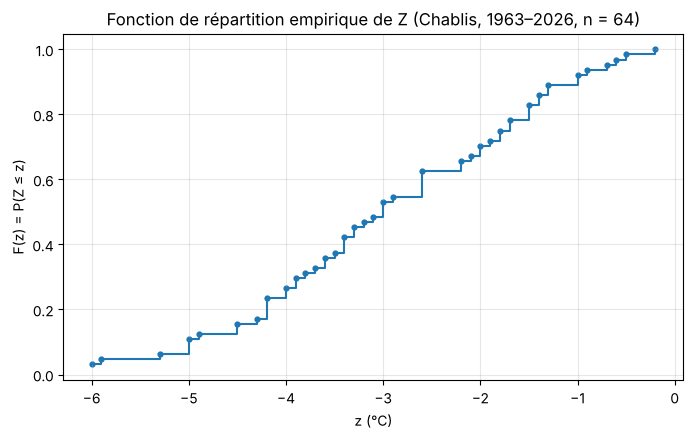

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.step(z_observes, F_emp(z_observes), where="post", color="tab:blue")
ax.scatter(z_observes, F_emp(z_observes), s=12, color="tab:blue")
ax.set_xlabel("z (°C)")
ax.set_ylabel("F(z) = P(Z ≤ z)")
ax.set_title("Fonction de répartition empirique de Z (Chablis, 1963–2026, n = 64)")
ax.grid(alpha=0.3)
plt.show()

In [4]:
LIMITE = 2_000_000

def prime_pure_integrale(z1, z2, F, echantillon):
    """l/(z1-z2) * intégrale de F sur [z2, z1], par rectangles exacts (F en escalier)."""
    sauts = np.sort(np.unique(echantillon))
    bornes = np.concatenate(([z2], sauts[(sauts > z2) & (sauts < z1)], [z1]))
    largeurs = np.diff(bornes)
    hauteurs = F(bornes[:-1])          # F est constante sur [bornes[k], bornes[k+1])
    return LIMITE / (z1 - z2) * np.sum(hauteurs * largeurs)

def prime_pure_rejeu(z1, z2, echantillon):
    """Moyenne des paiements que le contrat aurait versés chaque année."""
    paiements = LIMITE * np.clip((z1 - np.asarray(echantillon)) / (z1 - z2), 0, 1)
    return paiements.mean()

# Contrôle
for z1, z2 in [(-3, -5), (-4, -6), (-4.5, -5.5)]:
    a = prime_pure_integrale(z1, z2, F_emp, Z)
    b = prime_pure_rejeu(z1, z2, Z)
    assert np.isclose(a, b), (z1, z2, a, b)
    print(f"z1={z1}, z2={z2} : {a/1e3:.0f} k€")

z1=-3, z2=-5 : 533 k€
z1=-4, z2=-6 : 206 k€
z1=-4.5, z2=-5.5 : 178 k€


## Prime commerciale et choix de la structure $(z_1, z_2)$

Le budget de 200 k€ porte sur le prix payé par le client, pas sur la prime pure. Soit $X$ le paiement annuel du contrat.

- **Prime technique** (principe de l'écart-type) : $\pi_{\text{tech}} = \mathbb{E}[X] + \alpha\,\sigma(X)$
- **Prime commerciale**, frais et courtage $f$ exprimés en part de la prime commerciale :
  $P_{\text{comm}} = \pi_{\text{tech}} + f\,P_{\text{comm}} \iff P_{\text{comm}} = \dfrac{\pi_{\text{tech}}}{1-f}$

$\mathbb{E}[X]$ et $\sigma(X)$ sont estimés sur les paiements rejoués des 64 années (loi empirique).

**Hypothèses.** $\alpha \in \{0{,}1 ;\ 0{,}2 ;\ 0{,}3\}$ et $f \in \{10\,\% ;\ 20\,\% ;\ 30\,\%\}$

**Contraintes**, pour chaque couple $(\alpha, f)$ :
- $P_{\text{comm}} \le 200$ k€ ;
- 2021 déclenche un paiement : $z_1 > Z_{2021} = -4{,}9$ °C ;
- $z_2 \ge -6$ °C (pas d'observation plus froide), pas de 0,1 °C.

**Critère de choix** : la structure qui paie la plus grande part $p$ de la limite en 2021,
$p = \min\!\left(1, \dfrac{z_1 - Z_{2021}}{z_1 - z_2}\right)$ ; à égalité, la prime la plus proche du budget.

Le même critère départage ensuite les scénarios $(\alpha, f)$ faisables : on retient celui dont la structure paie la plus grande part de 2021.

In [5]:
BUDGET = 200_000
Z_2021 = Z.loc[2021]
Z2_MIN = -6.0
ALPHAS = [0.1, 0.2, 0.3]          # chargement de sécurité (hypothèse)
FRAIS = [0.10, 0.20, 0.30]        # frais et courtage, en part de la prime commerciale (hypothèse)

def paiements_rejoues(z1, z2, echantillon):
    return LIMITE * np.clip((z1 - np.asarray(echantillon)) / (z1 - z2), 0, 1)

def prime_commerciale(z1, z2, echantillon, alpha, f):
    X = paiements_rejoues(z1, z2, echantillon)
    prime_technique = X.mean() + alpha * X.std()      # std population : loi empirique des 64 années
    return prime_technique / (1 - f)

def part_2021(z1, z2):
    return min(1.0, max(0.0, (z1 - Z_2021) / (z1 - z2)))

# Grille de couples, en dixièmes de degré entiers pour éviter les erreurs d'arrondi
k_2021 = int(round(Z_2021 * 10))
grille = [(k1 / 10, k2 / 10)
          for k1 in range(-5, k_2021, -1)                      # z1 de -0,5 à -4,8 °C (> Z_2021)
          for k2 in range(k1 - 1, int(round(Z2_MIN * 10)) - 1, -1)]   # z2 de z1 - 0,1 à -6 °C

# Contrôle : la moyenne des paiements rejoués redonne la prime pure déjà validée
assert np.isclose(paiements_rejoues(-4.5, -5.3, Z).mean(), prime_pure_rejeu(-4.5, -5.3, Z))

resultats = []
for alpha in ALPHAS:
    for f in FRAIS:
        admissibles = []
        for z1, z2 in grille:
            P = prime_commerciale(z1, z2, Z, alpha, f)
            if P <= BUDGET:
                admissibles.append((part_2021(z1, z2), P, z1, z2))
        # Couple le moins cher de la grille : mesure l'écart au budget quand rien n'est admissible.
        # La prime est proportionnelle à la limite, d'où la limite maximale finançable par le budget.
        P_min = min(prime_commerciale(z1, z2, Z, alpha, f) for z1, z2 in grille)
        ligne = {"alpha": alpha, "f": f, "n_admissibles": len(admissibles),
                 "prime_comm_min": P_min, "limite_max": LIMITE * BUDGET / P_min}
        if admissibles:
            p, P, z1, z2 = max(admissibles)                    # max de p, puis prime la plus haute
            ligne.update({"z1": z1, "z2": z2, "p_2021": p, "prime_pure": prime_pure_rejeu(z1, z2, Z),
                          "prime_comm": P, "freq_paiement": (Z < z1).mean()})
        resultats.append(ligne)

resultats = pd.DataFrame(resultats)
affiche = resultats.assign(**{"p_2021_%": (100 * resultats["p_2021"]).round(0),
                              "prime_pure_k€": (resultats["prime_pure"] / 1e3).round(0),
                              "prime_comm_k€": (resultats["prime_comm"] / 1e3).round(0),
                              "freq_paiement_%": (100 * resultats["freq_paiement"]).round(0),
                              "prime_comm_min_k€": (resultats["prime_comm_min"] / 1e3).round(0),
                              "limite_max_M€": (resultats["limite_max"] / 1e6).round(2)})
print("Structure retenue par scénario (NaN = aucun couple ne respecte le budget)")
print(affiche[["alpha", "f", "n_admissibles", "z1", "z2", "p_2021_%", "prime_pure_k€", "prime_comm_k€",
               "freq_paiement_%"]].to_string(index=False))
print("\nPrime commerciale minimale atteignable (2021 payé) et limite maximale finançable par 200 k€")
print(affiche[["alpha", "f", "prime_comm_min_k€", "limite_max_M€"]].to_string(index=False))

Structure retenue par scénario (NaN = aucun couple ne respecte le budget)
 alpha   f  n_admissibles   z1   z2  p_2021_%  prime_pure_k€  prime_comm_k€  freq_paiement_%
   0.1 0.1              5 -4.7 -6.0      15.0          132.0          195.0             12.0
   0.1 0.2              0  NaN  NaN       NaN            NaN            NaN              NaN
   0.1 0.3              0  NaN  NaN       NaN            NaN            NaN              NaN
   0.2 0.1              0  NaN  NaN       NaN            NaN            NaN              NaN
   0.2 0.2              0  NaN  NaN       NaN            NaN            NaN              NaN
   0.2 0.3              0  NaN  NaN       NaN            NaN            NaN              NaN
   0.3 0.1              0  NaN  NaN       NaN            NaN            NaN              NaN
   0.3 0.2              0  NaN  NaN       NaN            NaN            NaN              NaN
   0.3 0.3              0  NaN  NaN       NaN            NaN            NaN              

In [6]:
# Part de la limite versée en 2021, selon les hypothèses de chargement (NaN = infaisable)
print(resultats.pivot(index="alpha", columns="f", values="p_2021").mul(100).round(0)
      .rename(columns=lambda f: f"f = {f:.0%}").to_string())

f      f = 10%  f = 20%  f = 30%
alpha                           
0.1       15.0      NaN      NaN
0.2        NaN      NaN      NaN
0.3        NaN      NaN      NaN


In [7]:
# Structure retenue : parmi les scénarios (alpha, f) faisables, celle qui paie la plus grande part de 2021
# (à égalité, la prime commerciale la plus proche du budget)
faisables = resultats.dropna(subset=["z1"])
assert not faisables.empty, "aucun scénario ne respecte le budget : revoir le mandat"
retenue = faisables.sort_values(["p_2021", "prime_comm"], ascending=False).iloc[0]
Z1, Z2 = retenue["z1"], retenue["z2"]

# Contrôle : les deux calculs de la prime pure coïncident pour la structure retenue
assert np.isclose(prime_pure_integrale(Z1, Z2, F_emp, Z), prime_pure_rejeu(Z1, Z2, Z))
print(f"{len(faisables)} scénario(s) faisable(s) sur {len(resultats)}")
print(f"Scénario retenu : alpha = {retenue['alpha']}, f = {retenue['f']:.0%}")
print(f"Structure retenue : z1 = {Z1} °C, z2 = {Z2} °C, 2021 payé à {retenue['p_2021']:.0%}, "
      f"prime pure {retenue['prime_pure']/1e3:.0f} k€, prime commerciale {retenue['prime_comm']/1e3:.0f} k€")

# Paiements que la structure retenue aurait versés (années avec paiement)
historique = pd.DataFrame({"Z": Z, "paiement_k€": paiements_rejoues(Z1, Z2, Z) / 1e3})
print(historique[historique["paiement_k€"] > 0].sort_values("Z").round(1).to_string())

1 scénario(s) faisable(s) sur 9
Scénario retenu : alpha = 0.1, f = 10%
Structure retenue : z1 = -4.7 °C, z2 = -6.0 °C, 2021 payé à 15%, prime pure 132 k€, prime commerciale 195 k€
         Z  paiement_k€
annee                  
1973  -6.0       2000.0
1996  -6.0       2000.0
2022  -5.9       1846.2
1967  -5.3        923.1
1975  -5.0        461.5
1968  -5.0        461.5
2012  -5.0        461.5
2021  -4.9        307.7


## Loi GEV ajustée par maximum de vraisemblance

La structure est fixée sur la loi empirique. On ajuste ensuite une GEV sur $Y = -Z$ (la GEV modélise des maxima)
pour vérifier que la loi empirique n'est pas trompeuse dans la zone qui fait le prix, $[z_2, z_1]$.

Diagnostics : QQ-plot, fonctions de répartition superposées avec un regard ciblé sur $[z_2, z_1]$,
puis tests de Kolmogorov-Smirnov et d'Anderson-Darling avec p-values par bootstrap paramétrique.

xi = -0.252, mu = 2.430, sigma = 1.394
Borne physique estimée : Z >= -7.97 °C


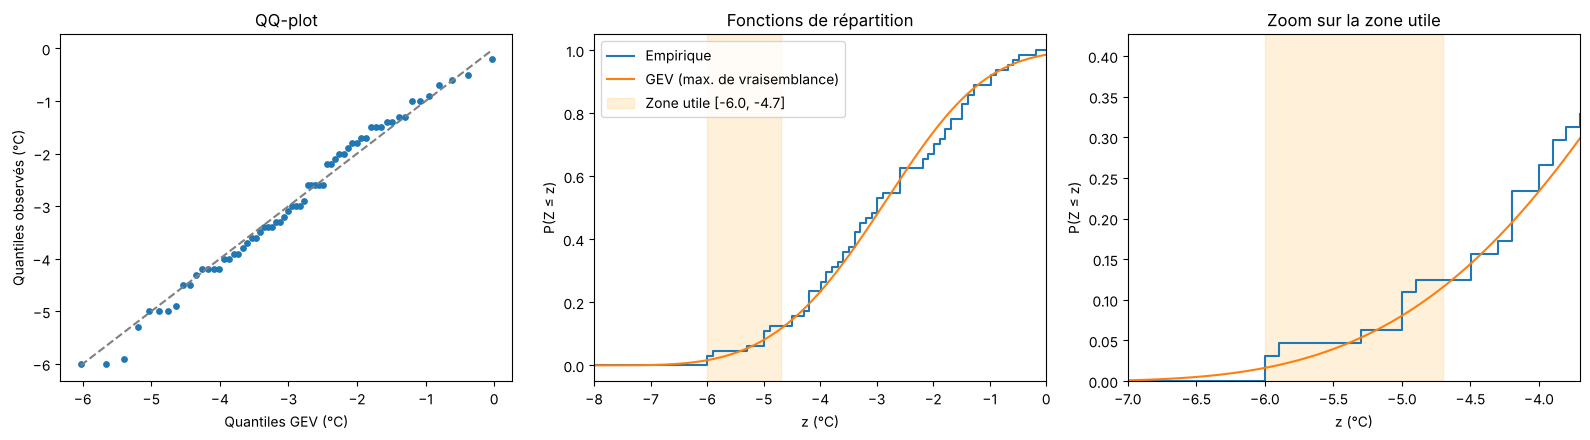

z = -6.0 : empirique 0.031, GEV 0.016
z = -4.9 : empirique 0.125, GEV 0.091
z = -4.7 : empirique 0.125, GEV 0.116
Prime pure : empirique 132 k€, GEV 110 k€


In [8]:
from scipy.stats import genextreme
from scipy.integrate import quad

# 1. Ajustement sur Y = -Z. Attention : scipy utilise c = -xi
Y = -Z.values
c, loc, scale = genextreme.fit(Y)
xi = -c
print(f"xi = {xi:.3f}, mu = {loc:.3f}, sigma = {scale:.3f}")
if xi < 0:
    print(f"Borne physique estimée : Z >= {-(loc - scale / xi):.2f} °C")

def F_gev(z):
    # P(Z <= z) sous la GEV ajustée
    return genextreme.sf(-z, c, loc=loc, scale=scale)

# 2. QQ-plot, fonctions de répartition, zoom sur la zone utile
n = len(Z)
z_tries = np.sort(Z.values)
probas = np.arange(1, n + 1) / (n + 1)                        # positions de tracé
z_theo = -genextreme.ppf(1 - probas, c, loc=loc, scale=scale)  # quantiles GEV de Z

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(z_theo, z_tries, s=15)
lim = [min(z_theo.min(), z_tries.min()), max(z_theo.max(), z_tries.max())]
axes[0].plot(lim, lim, color="grey", linestyle="--")
axes[0].set_xlabel("Quantiles GEV (°C)"); axes[0].set_ylabel("Quantiles observés (°C)")
axes[0].set_title("QQ-plot")

for ax, (gauche, droite) in zip(axes[1:], [(-8, 0), (Z2 - 1, Z1 + 1)]):
    g = np.linspace(gauche, droite, 400)
    ax.step(g, F_emp(g), where="post", label="Empirique")
    ax.plot(g, F_gev(g), label="GEV (max. de vraisemblance)")
    ax.axvspan(Z2, Z1, color="orange", alpha=0.15, label=f"Zone utile [{Z2}, {Z1}]")
    ax.set_xlim(gauche, droite); ax.set_xlabel("z (°C)"); ax.set_ylabel("P(Z ≤ z)")
axes[1].set_title("Fonctions de répartition"); axes[1].legend()
axes[2].set_title("Zoom sur la zone utile"); axes[2].set_ylim(0, F_emp(Z1 + 1) * 1.3)
plt.tight_layout(); plt.show()

# 3. Écart dans la zone utile, et prime pure de la structure retenue sous les deux lois
for z in sorted({Z2, Z_2021, Z1}):
    print(f"z = {z} : empirique {F_emp(z):.3f}, GEV {F_gev(z):.3f}")
prime_gev = LIMITE / (Z1 - Z2) * quad(F_gev, Z2, Z1)[0]
print(f"Prime pure : empirique {prime_pure_rejeu(Z1, Z2, Z)/1e3:.0f} k€, GEV {prime_gev/1e3:.0f} k€")

In [9]:
def moments_paiement_gev(z1, z2, c_, loc_, scale_):
    # E[X] et sigma(X) sous la GEV, avec X = l * g(Z), g(z) = min(1, (z1 - z)^+ / (z1 - z2))
    # Z = -Y : densité f_Z(z) = f_Y(-z), P(Z <= z) = P(Y >= -z)
    f_Z = lambda z: genextreme.pdf(-z, c_, loc=loc_, scale=scale_)
    F_Z = lambda z: genextreme.sf(-z, c_, loc=loc_, scale=scale_)
    g = lambda z: (z1 - z) / (z1 - z2)
    E_g = F_Z(z2) + quad(lambda z: g(z) * f_Z(z), z2, z1)[0]
    E_g2 = F_Z(z2) + quad(lambda z: g(z) ** 2 * f_Z(z), z2, z1)[0]
    return LIMITE * E_g, LIMITE * np.sqrt(max(E_g2 - E_g ** 2, 0.0))

def primes_gev(z1, z2, c_, loc_, scale_, alpha, f):
    moyenne, ecart_type = moments_paiement_gev(z1, z2, c_, loc_, scale_)
    return moyenne, (moyenne + alpha * ecart_type) / (1 - f)

ALPHA_R, F_R = retenue["alpha"], retenue["f"]     # hypothèses du scénario retenu
pure_gev, comm_gev = primes_gev(Z1, Z2, c, loc, scale, ALPHA_R, F_R)

# Contrôle : E[X] par la densité = formule intégrale de F
assert np.isclose(pure_gev, prime_gev, rtol=1e-6)
print(f"GEV : prime pure {pure_gev/1e3:.0f} k€, prime commerciale {comm_gev/1e3:.0f} k€ "
      f"(alpha = {ALPHA_R}, f = {F_R:.0%})")

GEV : prime pure 110 k€, prime commerciale 164 k€ (alpha = 0.1, f = 10%)


In [10]:
def stats_adequation(y):
    # Ajuste une GEV sur y, renvoie la statistique KS (D), Anderson-Darling (A2) et les paramètres
    c_, loc_, scale_ = genextreme.fit(y)
    u = np.clip(np.sort(genextreme.cdf(y, c_, loc=loc_, scale=scale_)), 1e-12, 1 - 1e-12)
    m = len(y); i = np.arange(1, m + 1)
    D = max(np.max(i / m - u), np.max(u - (i - 1) / m))
    A2 = -m - np.mean((2 * i - 1) * (np.log(u) + np.log(1 - u[::-1])))
    return D, A2, (c_, loc_, scale_)

D_obs, A2_obs, params = stats_adequation(Y)

# Bootstrap paramétrique : on simule sous la GEV ajustée, on RÉAJUSTE, on recalcule
# (statistiques de test -> p-values ; primes -> intervalle de confiance)
rng = np.random.default_rng(0)
B = 500
D_sim, A2_sim, primes_gev_boot = [], [], []
for _ in range(B):
    y_sim = np.round(genextreme.rvs(*params, size=len(Y), random_state=rng), 1)  # résolution 0,1 °C
    d, a, params_sim = stats_adequation(y_sim)
    D_sim.append(d); A2_sim.append(a)
    # même échantillon, même réajustement : prime recalculée -> intervalle de confiance de la prime GEV
    primes_gev_boot.append(primes_gev(Z1, Z2, *params_sim, ALPHA_R, F_R))

print(f"KS : D = {D_obs:.4f}, p-value = {np.mean(np.array(D_sim) >= D_obs):.2f}")
print(f"AD : A2 = {A2_obs:.4f}, p-value = {np.mean(np.array(A2_sim) >= A2_obs):.2f}")
primes_gev_boot = np.array(primes_gev_boot)        # colonnes : prime pure, prime commerciale

KS : D = 0.0678, p-value = 0.66
AD : A2 = 0.3435, p-value = 0.41


## Intervalles de confiance des primes

Deux bootstraps, chacun avec la méthode des percentiles (Efron et Tibshirani, 1993) :
- **empirique** (non paramétrique) : on tire 64 années avec remise parmi les 64 observées, on recalcule les primes ;
- **GEV** (paramétrique) : on simule 64 années sous la GEV ajustée, on réajuste, on recalcule les primes
  (mêmes échantillons que pour les p-values ci-dessus).

L'intervalle mesure l'incertitude d'estimation due à 64 années seulement. Il suppose des années
indépendantes et de même loi : une tendance climatique n'est pas prise en compte.
Limite de l'approche empirique : aucune année rééchantillonnée n'est plus froide que −6,0 °C ;
sans effet ici puisque $z_2 = -6{,}0$ °C plafonne le paiement.

In [11]:
# Bootstrap empirique : rééchantillonnage des années avec remise
rng = np.random.default_rng(1)
B_EMP = 5000
primes_emp_boot = []
for _ in range(B_EMP):
    echantillon = rng.choice(Z.values, size=len(Z), replace=True)
    primes_emp_boot.append((prime_pure_rejeu(Z1, Z2, echantillon),
                            prime_commerciale(Z1, Z2, echantillon, ALPHA_R, F_R)))
primes_emp_boot = np.array(primes_emp_boot)

def ic95(x):
    return np.percentile(x, [2.5, 97.5])

lignes = {}
for nom, estimation, boot in [
        ("Empirique", (prime_pure_rejeu(Z1, Z2, Z), prime_commerciale(Z1, Z2, Z, ALPHA_R, F_R)), primes_emp_boot),
        ("GEV (max. de vraisemblance)", (pure_gev, comm_gev), primes_gev_boot)]:
    (bp, hp), (bc, hc) = ic95(boot[:, 0]), ic95(boot[:, 1])
    lignes[nom] = {"prime pure (k€)": f"{estimation[0]/1e3:.0f}  [{bp/1e3:.0f} ; {hp/1e3:.0f}]",
                   "prime commerciale (k€)": f"{estimation[1]/1e3:.0f}  [{bc/1e3:.0f} ; {hc/1e3:.0f}]"}

print(f"Structure z1 = {Z1} °C, z2 = {Z2} °C, limite {LIMITE/1e6:.0f} M€, alpha = {ALPHA_R}, f = {F_R:.0%}")
print("Estimation  [IC 95 % par bootstrap percentile]\n")
print(pd.DataFrame(lignes).T.to_string())
print(f"\nPart des réplications bootstrap où la prime commerciale dépasse {BUDGET/1e3:.0f} k€ : "
      f"empirique {np.mean(primes_emp_boot[:, 1] > BUDGET):.0%}, GEV {np.mean(primes_gev_boot[:, 1] > BUDGET):.0%}")

Structure z1 = -4.7 °C, z2 = -6.0 °C, limite 2 M€, alpha = 0.1, f = 10%
Estimation  [IC 95 % par bootstrap percentile]

                             prime pure (k€) prime commerciale (k€)
Empirique                    132  [38 ; 248]        195  [65 ; 341]
GEV (max. de vraisemblance)  110  [24 ; 177]        164  [42 ; 253]

Part des réplications bootstrap où la prime commerciale dépasse 200 k€ : empirique 44%, GEV 19%
